# **LLM-as-a-Judge Reliability Analysis**

_An Experimental Study of Prompt Sensitivity and Positional Bias in Indonesian Language Evaluation_

**Research Metadata**

- Author: Rozhak
- Research Area: Natural Language Processing
- Research Topic: LLM-as-a-Judge Reliability
- Dataset: IndoPref
- Evaluator: `Qwen3-32B (Non-Thinking Mode, 8-bit INT8)`

**Evaluation Objectives**

- Measure positional consistency.
- Quantify decision flip rate.
- Analyze agreement with human preference using Cohen's Kappa.
- Examine the effect of prompt variations on judge reliability.

# **1. Introduction**

### **1.1 Research Background**

LLM-as-a-Judge digunakan untuk mengevaluasi kualitas respons Large Language Models (LLMs). Namun, keputusan evaluator dapat dipengaruhi oleh urutan penyajian kandidat (*position bias*) dan formulasi instruksi (*prompt sensitivity*). Hal ini menimbulkan pertanyaan mengenai konsistensi keputusan evaluator ketika kondisi pengujian berubah.

Penelitian ini mengkaji reliabilitas `Qwen3-32B` (Non-Thinking Mode, 8-bit INT8) dalam mengevaluasi respons berbahasa Indonesia menggunakan IndoPref sebagai acuan preferensi manusia (*human preference*). Pengujian difokuskan pada pengaruh variasi prompt dan pertukaran posisi kandidat terhadap keputusan evaluator.

### **1.2 Research Objectives**

Penelitian ini bertujuan untuk menganalisis reliabilitas `Qwen3-32B` (Non-Thinking Mode, 8-bit INT8) sebagai LLM-as-a-Judge melalui tiga aspek: kesesuaian keputusan dengan *human preference*, konsistensi keputusan ketika posisi kandidat ditukar, dan konsistensi keputusan terhadap variasi formulasi prompt.

### **1.3 Experimental Overview**

Eksperimen menggunakan 519 sampel IndoPref dengan tiga strategi prompt (P1, P2, P3) dan dua kondisi posisi kandidat (AB, BA). Seluruh kondisi dijalankan menggunakan Qwen3-32B (Non-Thinking Mode, 8-bit INT8) dengan konfigurasi inferensi yang sama, menghasilkan 3.114 inferensi.

Keputusan evaluator kemudian diproses dan dianalisis menggunakan metrik *Accuracy*, Cohen's Kappa, *Position Consistency*, *Preference Flip Rate*, serta *Prompt Consistency* dan *Prompt Flip Rate*.

### **1.4 Notebook Organization**

Notebook ini mencakup persiapan lingkungan komputasi dan dataset, pemuatan serta kuantisasi model, penyusunan prompt, pelaksanaan inferensi, pengukuran reliabilitas, dan visualisasi hasil evaluasi.

## **2. Environment Setup**

Menyiapkan dependensi, konfigurasi runtime, perangkat komputasi, dan direktori penyimpanan eksperimen.

### **2.1 Dependency Installation**

Menginstal dan mengimpor pustaka untuk pemrosesan dataset, inferensi model, kuantisasi, evaluasi statistik, dan visualisasi.

In [1]:
!pip install -q datasets pyarrow pandas matplotlib seaborn transformers accelerate bitsandbytes scikit-learn statsmodels

In [2]:
import datetime
import json
import os
import gc
import re
import time
import shutil
from typing import Tuple, List, Dict, Any, Optional

import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from datasets import load_dataset
from sklearn.model_selection import train_test_split

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar

print(
    f"[ENVIRONMENT] status=READY | "
    f"dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | "
    f"libraries=IMPORTED"
)

[ENVIRONMENT] status=READY | dependencies=torch,transformers,datasets,bitsandbytes,scikit-learn | libraries=IMPORTED


### **2.2 Hardware and Runtime Verification**

Menetapkan direktori proyek, `MODEL_ID`, dan `RANDOM_SEED`. Pemeriksaan CUDA mengidentifikasi ketersediaan GPU, nama perangkat, dan kapasitas VRAM.

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_RAW_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'raw')
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = '/content/models'
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = 'Qwen/Qwen3-32B'

RANDOM_SEED: int = 42

os.environ['HF_HOME'] = MODELS_DIR
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'

try:
    from transformers.utils import logging as hf_logging
    hf_logging.disable_progress_bar()
except Exception:
    pass

if torch.cuda.is_available():
    device_name: str = torch.cuda.get_device_name(0)
    vram_gb: float = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    device_info: str = f"CUDA | gpu='{device_name}' | vram={vram_gb:.2f} GB"
else:
    device_info: str = "CPU | warning=GPU_NOT_DETECTED"

print(
    f"[ENVIRONMENT] device={device_info} | "
    f"seed={RANDOM_SEED} | "
    f"model_id='{MODEL_ID}' | "
    f"status=CONFIGURED"
)

[ENVIRONMENT] device=CUDA | gpu='NVIDIA A100-SXM4-80GB' | vram=79.25 GB | seed=42 | model_id='Qwen/Qwen3-32B' | status=CONFIGURED


### **2.3 Storage and Authentication**

Menghubungkan Google Drive pada lingkungan Colab, membaca token Hugging Face dari `secrets.json`, serta menyiapkan direktori data dan hasil eksperimen di Google Drive dan direktori cache model pada disk lokal.

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')

    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r', encoding='utf-8') as f:
            secrets = json.load(f)
        hf_token: str = secrets.get('HF_TOKEN', '')
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
        else:
            print("[ENVIRONMENT] status=WARNING | component='HF_TOKEN not found in secrets.json'")
    else:
        print(f"[ENVIRONMENT] status=WARNING | component='secrets.json not found at {secrets_path}'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

for d in [DATA_RAW_DIR, DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

print("[ENVIRONMENT] status=READY | directories='all_initialized'")

Mounted at /content/drive
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'
[ENVIRONMENT] status=READY | directories='all_initialized'


## **3. Dataset Preparation**

Memuat dataset IndoPref, memvalidasi skema, menghapus duplikasi, dan membentuk dataset evaluasi yang disimpan dalam format Parquet.

### **3.1 Multi-Tier Ingestion and Cache Lookup**

Memeriksa cache dataset evaluasi dan data mentah secara berurutan. Jika cache tidak tersedia atau tidak memenuhi ketentuan ukuran, dataset diambil dari Hugging Face Hub (`davidanugraha/IndoPref`, split `test`).

In [5]:
eval_path: str = os.path.join(DATA_PROCESSED_DIR, 'indopref_eval_stratified.parquet')
raw_path: str = os.path.join(DATA_RAW_DIR, 'indopref_raw.parquet')

EVAL_SAMPLE_SIZE: Optional[int] = None # 150
FORCE_REGENERATE_DATA: bool = False # True

df_raw: Optional[pd.DataFrame] = None
df_clean: Optional[pd.DataFrame] = None
df_eval: Optional[pd.DataFrame] = None

use_existing_silver: bool = False
if os.path.exists(eval_path) and not FORCE_REGENERATE_DATA:
    cached_silver = pd.read_parquet(eval_path)
    size_matched = (
        (EVAL_SAMPLE_SIZE is None and len(cached_silver) >= 500) or
        (EVAL_SAMPLE_SIZE is not None and len(cached_silver) == EVAL_SAMPLE_SIZE)
    )
    if size_matched:
        df_eval = cached_silver
        use_existing_silver = True
        print(f"[DATASET] status=CACHE_HIT | tier='processed_silver' | samples={len(df_eval)} | path='{eval_path}'")
    else:
        target_str = 'FULL (>=500)' if EVAL_SAMPLE_SIZE is None else str(EVAL_SAMPLE_SIZE)
        print(f"[DATASET] status=CACHE_INVALIDATED | reason='sample_size_changed' | cached={len(cached_silver)} | target={target_str}")

if not use_existing_silver:
    if os.path.exists(raw_path):
        df_raw = pd.read_parquet(raw_path)
        print(f"[DATASET] status=CACHE_HIT | tier='raw_bronze' | records={len(df_raw)} | path='{raw_path}'")
    else:
        print("[DATASET] status=CACHE_MISS | tier='remote_fetch' | id='davidanugraha/IndoPref'")
        dataset = load_dataset('davidanugraha/IndoPref', split='test')
        df_raw = dataset.to_pandas()
        print(f"[DATASET] status=FETCHED_REMOTE | raw_records={len(df_raw)}")

[DATASET] status=CACHE_HIT | tier='processed_silver' | samples=519 | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_eval_stratified.parquet'


### **3.2 Schema Validator Definition**

Mendefinisikan validator untuk enam kolom wajib: `original_id`, `domain`, `input`, `response_1`, `response_2`, dan `actual_score`. Pemeriksaan mencakup kolom yang hilang, nilai null, dan string kosong pada kolom teks.

In [6]:
def validate_dataset_schema(df: pd.DataFrame) -> bool:
    required_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
    missing = [c for c in required_cols if c not in df.columns]

    if missing:
        print(f"[VALIDATION] status=FAILED | error='missing_columns' | columns={missing}")
        return False
    if df[required_cols].isnull().sum().sum() > 0:
        print("[VALIDATION] status=FAILED | error='null_values'")
        return False
    for col in ['input', 'response_1', 'response_2']:
        if (df[col].astype(str).str.strip() == '').any():
            print(f"[VALIDATION] status=FAILED | error='empty_string' | column='{col}'")
            return False
        
    print("[VALIDATION] status=PASSED | schema='valid'")
    return True

### **3.3 Schema Integrity Verification**

Menjalankan validator pada dataset evaluasi atau data mentah. Proses dihentikan dengan `ValueError` apabila validasi gagal.

In [7]:
target_df_to_check = df_eval if df_eval is not None else df_raw
if not validate_dataset_schema(target_df_to_check):
    raise ValueError("[VALIDATION] error='schema_verification_failed'")

print(
    f"[VALIDATION] dataset_shape={target_df_to_check.shape} | "
    f"required_columns={len(['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score'])} | "
    f"null_counts=0 | "
    f"empty_strings=0 | "
    f"status=PASSED"
)

[VALIDATION] status=PASSED | schema='valid'
[VALIDATION] dataset_shape=(519, 10) | required_columns=6 | null_counts=0 | empty_strings=0 | status=PASSED


### **3.4 Sample Deduplication**

Menghapus duplikasi berdasarkan `original_id` pada jalur data mentah. Tahap ini dilewati jika dataset evaluasi telah dimuat dari cache terproses.

In [8]:
if df_eval is None and df_raw is not None:
    duplicates: int = int(df_raw.duplicated(subset=['original_id']).sum())
    if duplicates > 0:
        df_clean = df_raw.drop_duplicates(subset=['original_id']).copy()
        print(f"[VALIDATION] status=DEDUPLICATED | removed={duplicates} | remaining={len(df_clean)}")
    else:
        df_clean = df_raw.copy()
        print(f"[VALIDATION] status=CLEAN | records={len(df_clean)}")
    if not os.path.exists(raw_path):
        df_clean.to_parquet(raw_path, index=False)
        print(f"[DATASET] status=PERSISTED_BRONZE | path='{raw_path}'")
else:
    print("[VALIDATION] status=SKIPPED_DEDUP | reason='Loaded from pre-validated silver cache'")

[VALIDATION] status=SKIPPED_DEDUP | reason='Loaded from pre-validated silver cache'


### **3.5 Evaluation Cohort Sampling**

Menggunakan seluruh data bersih ketika `EVAL_SAMPLE_SIZE=None`. Jika ukuran sampel ditentukan dan jumlah data melebihinya, `train_test_split` menerapkan stratifikasi berdasarkan `domain` dengan `RANDOM_SEED`. Hasilnya disimpan sebagai Parquet.

In [9]:
if df_eval is None and df_clean is not None:
    if EVAL_SAMPLE_SIZE is not None and len(df_clean) > EVAL_SAMPLE_SIZE:
        df_eval, _ = train_test_split(
            df_clean,
            train_size=EVAL_SAMPLE_SIZE,
            stratify=df_clean['domain'],
            random_state=RANDOM_SEED
        )
        print(f"[DATASET] status=PERSISTED_SILVER | cohort_mode=subsample | samples={len(df_eval)} | stratify=domain | path='{eval_path}'")
    else:
        df_eval = df_clean.copy()
        print(f"[DATASET] status=PERSISTED_SILVER | cohort_mode=full_census | samples={len(df_eval)} | domain_balanced=True | path='{eval_path}'")
    df_eval.to_parquet(eval_path, index=False)
else:
    print(f"[DATASET] status=REUSED_SILVER | cohort_mode=full_census | samples={len(df_eval)} | path='{eval_path}'")

[DATASET] status=REUSED_SILVER | cohort_mode=full_census | samples=519 | path='/content/drive/MyDrive/LLMReliability/data/processed/indopref_eval_stratified.parquet'


### **3.6 Dataset Inspection and Sample Profiling**

Menampilkan jumlah baris, penggunaan memori, distribusi domain, serta contoh `input`, respons kandidat, dan `actual_score`.

In [10]:
display_cols: List[str] = ['original_id', 'domain', 'input', 'response_1', 'response_2', 'actual_score']
print(f"[DATASET_INSPECTION] total_samples={len(df_eval)} | memory_usage={df_eval.memory_usage().sum() / 1024:.1f} KB")
display(df_eval[display_cols].head(3))

print("[DATASET_DISTRIBUTION] Komposisi Sampel per Domain:")
domain_dist = df_eval['domain'].value_counts().to_frame(name='Jumlah Sampel')
domain_dist['Persentase (%)'] = (domain_dist['Jumlah Sampel'] / len(df_eval) * 100).round(2)
display(domain_dist)

sample_row = df_eval.iloc[0]
raw_actual = str(sample_row.get('actual_score', 'N/A'))
print(f"[SAMPLE_METADATA] id={sample_row['original_id']} | domain='{sample_row['domain']}'")
print(f"[SAMPLE_INPUT] {sample_row['input']}")
print(f"[SAMPLE_RESPONSE_1] length={len(sample_row['response_1'])} chars | text:\n{sample_row['response_1']}")
print(f"[SAMPLE_RESPONSE_2] length={len(sample_row['response_2'])} chars | text:\n{sample_row['response_2']}")
print(f"[SAMPLE_GROUND_TRUTH] actual_score='{raw_actual}'")

[DATASET_INSPECTION] total_samples=519 | memory_usage=40.7 KB


,original_id,domain,input,response_1,response_2,actual_score
0,175,logic,Jika Anda menambah kecepatan kendaraan tiba-ti...,Jika Anda menambah kecepatan kendaraan tiba-ti...,Jika Anda menambah kecepatan kendaraan tiba-ti...,Assistant A
1,416,brainstorming,Jika Anda memiliki kesempatan untuk memulai ke...,Pertanyaan ini sangat menarik dan bisa memilik...,Keputusan untuk memulai kembali hidup di tempa...,Assistant B
2,140,logic,"Sebuah taman memiliki tiga jenis bunga: mawar,...",Melati berada di sebelah **mawar**. \n\nBeriku...,"Berdasarkan informasi yang diberikan, kita dap...",Assistant A


[DATASET_DISTRIBUTION] Komposisi Sampel per Domain:


,Jumlah Sampel,Persentase (%)
domain,,
brainstorming,70,13.49
translation,56,10.79
logic,53,10.21
summarization,50,9.63
analysis,50,9.63
open question,50,9.63
coding,50,9.63
math,49,9.44
safety,46,8.86


[SAMPLE_METADATA] id=175 | domain='logic'
[SAMPLE_INPUT] Jika Anda menambah kecepatan kendaraan tiba-tiba, apa efeknya pada rem?
[SAMPLE_RESPONSE_1] length=1324 chars | text:
Jika Anda menambah kecepatan kendaraan tiba-tiba (atau melakukan akselerasi cepat), efeknya pada rem akan signifikan dan dapat dijelaskan sebagai berikut:

1. **Tingkat Kekuatan Rem Meningkat**: Ketika Anda menekan pedal gas dengan kuat untuk mempercepat kendaraan, mesin menghasilkan torsi yang lebih besar, yang mendorong roda untuk berputar lebih cepat. Untuk menjaga kontrol kendaraan dan memperlambat atau berhenti, sistem rem harus bekerja lebih keras. Hal ini menyebabkan peningkatan kekuatan rem secara keseluruhan.

2. **Peningkatan Tekanan Rem**: Dalam situasi akselerasi cepat, sistem rem dirancang untuk menyesuaikan tekanan rem pada setiap roda secara individu. Rem di roda depan dan belakang mungkin mengalami tekanan yang lebih tinggi dibandingkan saat berkendara dengan kecepatan konstan. Hal ini memungkinkan

## **4. Model Loading and Quantization**

Menyiapkan tokenizer dan model `Qwen3-32B` dengan konfigurasi kuantisasi 8-bit.

### **4.1 Tokenizer Initialization**

Memuat tokenizer berdasarkan `MODEL_ID` dan direktori cache lokal `MODELS_DIR`, kemudian menampilkan ukuran vocabulary.

In [ ]:
print(f"[MODEL] id='{MODEL_ID}' | status=LOADING_TOKENIZER")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, cache_dir=MODELS_DIR)
print(f"[MODEL] status=TOKENIZER_READY | vocab_size={tokenizer.vocab_size}")

[MODEL] id='Qwen/Qwen3-32B' | status=LOADING_TOKENIZER
[MODEL] status=TOKENIZER_READY | vocab_size=151643


### **4.2 8-Bit Quantization Configuration**

Mengatur `BitsAndBytesConfig` dengan konfigurasi 8-bit (`load_in_8bit=True`).

In [12]:
bnb_config = BitsAndBytesConfig(
    load_in_8bit=True,
)

print(
    f"[QUANTIZATION] method='bitsandbytes_8bit' | "
    f"status=CONFIGURED"
)

[QUANTIZATION] method='bitsandbytes_8bit' | status=CONFIGURED


### **4.3 Weight Loading and Memory Profiling**

Memuat model menggunakan konfigurasi kuantisasi dan `device_map='auto'`. Jika ditemukan indikasi kerusakan cache Safetensors, kode membersihkan cache terkait dan mengulangi pemuatan dengan `force_download`. Penggunaan VRAM allocated dan reserved kemudian dicatat.

In [13]:
print(f"[MODEL] id='{MODEL_ID}' | status=LOADING_MODEL | cache_dir='{MODELS_DIR}'")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    quantization_config=bnb_config,
    device_map='auto',
    cache_dir=MODELS_DIR
)

allocated_vram: float = torch.cuda.memory_allocated() / (1024**3)
reserved_vram: float = torch.cuda.memory_reserved() / (1024**3)

print(f"[MODEL] status=LOADED | device={model.device} | allocated_vram={allocated_vram:.2f} GB | reserved_vram={reserved_vram:.2f} GB")

[MODEL] id='Qwen/Qwen3-32B' | status=LOADING_MODEL | cache_dir='/content/models'
[MODEL] status=LOADED | device=cuda:0 | allocated_vram=31.98 GB | reserved_vram=32.60 GB


## **5. Prompt Engineering**

Mendefinisikan tiga strategi prompt evaluasi: P1 Baseline, P2 Multi-criteria, dan P3 RCAF Constraint.

### **5.1 Prompt Strategy Definition**

Fungsi `format_prompt` membentuk instruksi berdasarkan strategi berikut:

- **P1 – Baseline:** perbandingan respons secara holistik.
- **P2 – Multi-criteria:** perbandingan berdasarkan akurasi, relevansi, dan kejelasan.
- **P3 – RCAF Constraint:** instruksi untuk mengabaikan posisi kandidat dan panjang respons.

In [14]:
def format_prompt(input_text: str, resp_A: str, resp_B: str, p_id: str) -> str:
    if p_id == 'P1':
        return (
            f"### TUGAS\nBandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nKeluarkan HANYA satu huruf: A atau B. Dilarang menulis alasan atau teks lain."
        )
    elif p_id == 'P2':
        return (
            f"### TUGAS\nNilai dua respons AI berikut berdasarkan: Akurasi (kebenaran), Relevansi (menjawab instruksi), dan Kejelasan (tidak bertele-tele).\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### FORMAT JAWABAN\nBerdasarkan kriteria di atas, keluarkan HANYA satu huruf: A atau B. Dilarang memberikan penjelasan."
        )
    elif p_id == 'P3':
        return (
            f"### TUGAS\nTentukan respons terbaik untuk instruksi di bawah ini.\n\n"
            f"### INSTRUKSI\n{input_text}\n\n"
            f"### RESPONS A\n{resp_A}\n\n"
            f"### RESPONS B\n{resp_B}\n\n"
            f"### ATURAN KETAT\n- Abaikan urutan kemunculan respons (jangan bias posisi).\n- Abaikan panjang respons (jangan bias verbosity).\n- FORMAT JAWABAN WAJIB: Keluarkan hanya karakter A atau B."
        )
    return ""

print("[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED")

[PROMPT_ENGINEERING] strategies=['P1_Baseline', 'P2_MultiCriteria', 'P3_RCAF'] | status=FUNCTIONS_DEFINED


### **5.2 Chat Template Formatting**

Menerapkan chat template Qwen3 dengan pesan system dan user dalam format Non-Thinking (`enable_thinking=False`). Pesan system menetapkan peran evaluator, sedangkan pesan user memuat instruksi dan pasangan respons. Format keluaran dibatasi pada pilihan `A` atau `B` secara langsung tanpa penalaran pemikiran internal.

In [15]:
def apply_chat_template(tokenizer, text: str, enable_thinking: bool = False) -> str:
    messages = [
        {'role': 'system', 'content': 'Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat (A atau B).'},
        {'role': 'user', 'content': text}
    ]
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

print("[CHAT_TEMPLATE] model='Qwen3-32B' | mode='non_thinking' | add_generation_prompt=True | status=CONFIGURED")

[CHAT_TEMPLATE] model='Qwen3-32B' | mode='non_thinking' | add_generation_prompt=True | status=CONFIGURED


### **5.3 Concrete Prompt Inspection**

Menampilkan prompt P1 pada urutan AB dan BA serta prompt P3 pada urutan AB, termasuk jumlah token setelah chat template diterapkan.

In [16]:
demo_sample = df_eval.iloc[0]
demo_input: str = demo_sample['input']
resp_1: str = demo_sample['response_1']
resp_2: str = demo_sample['response_2']

prompt_p1_ab: str = format_prompt(demo_input, resp_1, resp_2, p_id='P1')
chat_p1_ab: str = apply_chat_template(tokenizer, prompt_p1_ab)
tokens_ab: int = len(tokenizer.encode(chat_p1_ab))

prompt_p1_ba: str = format_prompt(demo_input, resp_2, resp_1, p_id='P1')
chat_p1_ba: str = apply_chat_template(tokenizer, prompt_p1_ba)
tokens_ba: int = len(tokenizer.encode(chat_p1_ba))

print(f"[PROMPT_INSPECTION] condition='AB' | strategy='P1' | tokens={tokens_ab}")
print(chat_p1_ab)
print(f"[PROMPT_INSPECTION] condition='BA' | strategy='P1' | tokens={tokens_ba}")
print(chat_p1_ba)

prompt_p3_ab: str = format_prompt(demo_input, resp_1, resp_2, p_id='P3')
chat_p3_ab: str = apply_chat_template(tokenizer, prompt_p3_ab)
tokens_p3: int = len(tokenizer.encode(chat_p3_ab))
print(f"[PROMPT_INSPECTION] condition='AB' | strategy='P3_RCAF' | tokens={tokens_p3} | status=VERIFIED")

[PROMPT_INSPECTION] condition='AB' | strategy='P1' | tokens=798
<|im_start|>system
Anda adalah evaluator AI yang objektif. Anda tidak memiliki bias posisi. Jawab HANYA dengan pilihan kandidat (A atau B).<|im_end|>
<|im_start|>user
### TUGAS
Bandingkan dua respons AI di bawah ini untuk instruksi yang sama. Pilih mana yang secara keseluruhan lebih baik.

### INSTRUKSI
Jika Anda menambah kecepatan kendaraan tiba-tiba, apa efeknya pada rem?

### RESPONS A
Jika Anda menambah kecepatan kendaraan tiba-tiba (atau melakukan akselerasi cepat), efeknya pada rem akan signifikan dan dapat dijelaskan sebagai berikut:

1. **Tingkat Kekuatan Rem Meningkat**: Ketika Anda menekan pedal gas dengan kuat untuk mempercepat kendaraan, mesin menghasilkan torsi yang lebih besar, yang mendorong roda untuk berputar lebih cepat. Untuk menjaga kontrol kendaraan dan memperlambat atau berhenti, sistem rem harus bekerja lebih keras. Hal ini menyebabkan peningkatan kekuatan rem secara keseluruhan.

2. **Peningkatan Te

## **6. Model Inference**

Menjalankan evaluasi pada kombinasi sampel, tiga strategi prompt, dan dua urutan kandidat. Hasil dicatat dalam JSONL untuk mendukung kelanjutan eksekusi.

### **6.1 Inference Progress Tracking**

Mendefinisikan `log_progress` untuk mencatat jumlah tugas, persentase penyelesaian, waktu berjalan, dan metrik inferensi tambahan. Log diperbarui setiap 15 tugas atau saat proses selesai.

In [17]:
def log_progress(current: int, total: int, session_start: float, log_interval: int = 15, **kwargs):
    if (current % log_interval == 0) or (current >= total):
        elapsed: float = time.time() - session_start
        pct: float = (current / total) * 100.0 if total > 0 else 0.0
        metrics_str: str = ' | '.join([f"{k}={v}" for k, v in kwargs.items()])
        print(f"[EVALUATION] {pct:.1f}% ({current}/{total}) | elapsed={elapsed:.1f}s | {metrics_str}")

print("[EVALUATION] status=LOGGER_READY | log_interval=15")

[EVALUATION] status=LOGGER_READY | log_interval=15


### **6.2 Symmetric Paired Evaluation**

Membentuk kombinasi evaluasi untuk setiap sampel, prompt, dan posisi AB/BA. Preferensi manusia dipetakan sesuai posisi kandidat yang ditampilkan.

Inferensi menggunakan `do_sample=False` dan `max_new_tokens=10`. Setiap hasil mencatat identitas sampel, domain, prompt, posisi, preferensi manusia, keluaran model, waktu eksekusi, jumlah token, dan throughput.

Hasil ditambahkan ke JSONL setelah setiap inferensi. Kombinasi yang sudah tercatat dilewati saat eksekusi ulang, kemudian objek inferensi dan cache GPU dibersihkan.

In [18]:
out_file: str = os.path.join(RESULTS_DIR, 'main_outputs_final.jsonl')
prompts: List[str] = ['P1', 'P2', 'P3']
positions: List[str] = ['AB', 'BA']

def determine_human_winner(row_data: Any) -> str:
    if 'actual_score' in row_data:
        val: str = str(row_data['actual_score']).strip().upper()
        if 'ASSISTANT A' in val or val in ['A', '1', '1.0']:
            return 'A'
        if 'ASSISTANT B' in val or val in ['B', '2', '2.0']:
            return 'B'
        try:
            parsed_val = json.loads(str(row_data['actual_score']).replace("'", '"'))
            if isinstance(parsed_val, (list, tuple)) and len(parsed_val) >= 2:
                return 'A' if float(parsed_val[0]) >= float(parsed_val[1]) else 'B'
        except Exception:
            pass
    if 'model_1' in row_data and 'chosen_model' in row_data:
        if str(row_data['chosen_model']).strip() == str(row_data['model_1']).strip():
            return 'A'
        elif 'rejected_model' in row_data and str(row_data['rejected_model']).strip() == str(row_data['model_1']).strip():
            return 'B'
    if 'label' in row_data:
        l_val: str = str(row_data['label']).strip().upper()
        if 'ASSISTANT A' in l_val or l_val in ['1', '0', 'A']:
            return 'A'
        if 'ASSISTANT B' in l_val or l_val in ['2', 'B']:
            return 'B'
    return 'A'

In [19]:
processed_combinations: set = set()
if os.path.exists(out_file):
    with open(out_file, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                record_item = json.loads(line)
                processed_combinations.add((record_item['sample_id'], record_item['prompt_id'], record_item['position']))

target_tasks: List[Dict[str, Any]] = []
for _, row in df_eval.iterrows():
    s_id: int = int(row['original_id'])
    for p_id in prompts:
        for pos in positions:
            target_tasks.append({
                'row': row,
                'sample_id': s_id,
                'prompt_id': p_id,
                'position': pos,
                'key': (s_id, p_id, pos)
            })

total_cohort_tasks: int = len(target_tasks)
pending_tasks: List[Dict[str, Any]] = [t for t in target_tasks if t['key'] not in processed_combinations]
already_completed: int = total_cohort_tasks - len(pending_tasks)

print(f"[RESUME] cohort_total={total_cohort_tasks} | already_completed={already_completed} | pending={len(pending_tasks)}")
print(f"[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='{out_file}'")

[RESUME] cohort_total=3114 | already_completed=3114 | pending=0
[INFERENCE_CONFIG] sampling=False | max_new_tokens=10 | temperature=0.0 | format='JSONL' | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


In [20]:
if not pending_tasks:
    print("[INFERENCE] status=ALREADY_COMPLETED | All cohort tasks exist in results.")
else:
    print(f"[INFERENCE] status=STARTED | remaining_evaluations={len(pending_tasks)}")
    current_step: int = already_completed
    inference_start_t: float = time.time()
    with torch.no_grad():
        for task in pending_tasks:
            current_step += 1
            row = task['row']
            sample_id = task['sample_id']
            p_id = task['prompt_id']
            pos = task['position']

            human_winner: str = determine_human_winner(row)
            if pos == 'AB':
                resp_A, resp_B = row['response_1'], row['response_2']
                current_human = human_winner
            else:
                resp_A, resp_B = row['response_2'], row['response_1']
                current_human = 'B' if human_winner == 'A' else 'A'

            start_t: float = time.time()
            raw_prompt: str = format_prompt(row['input'], resp_A, resp_B, p_id)
            formatted_prompt: str = apply_chat_template(tokenizer, raw_prompt)
            inputs = tokenizer(formatted_prompt, return_tensors='pt').to(model.device)

            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

            gen_tokens = outputs[0][inputs['input_ids'].shape[1]:]
            raw_out: str = tokenizer.decode(gen_tokens, skip_special_tokens=True)
            runtime_sec: float = round(time.time() - start_t, 2)
            tps: float = round(len(gen_tokens) / runtime_sec, 2) if runtime_sec > 0 else 0.0

            record: Dict[str, Any] = {
                'sample_id': sample_id,
                'domain': row['domain'],
                'prompt_id': p_id,
                'position': pos,
                'human_preference': current_human,
                'raw_output': raw_out,
                'runtime_sec': runtime_sec,
                'output_tokens': len(gen_tokens),
                'tps': tps
            }

            with open(out_file, 'a', encoding='utf-8') as f:
                f.write(json.dumps(record) + '\n')
                f.flush()

            processed_combinations.add((sample_id, p_id, pos))
            log_progress(current_step, total_cohort_tasks, inference_start_t, log_interval=15, ID=sample_id, Prompt=p_id, Pos=pos, TPS=tps)

            del inputs, outputs
            torch.cuda.empty_cache()
            gc.collect()

print(f"[INFERENCE] status=COMPLETED | sink='{out_file}'")

[INFERENCE] status=ALREADY_COMPLETED | All cohort tasks exist in results.
[INFERENCE] status=COMPLETED | sink='/content/drive/MyDrive/LLMReliability/results/main_outputs_final.jsonl'


## **7. Reliability Metric Evaluation**

Memproses keluaran inferensi dan menghitung metrik keselarasan preferensi manusia, konsistensi posisi, serta stabilitas prompt.

### **7.1 Decision Extraction and Mapping**

Mengekstrak label `A` atau `B` dari keluaran model menggunakan `parse_decision`. Keluaran yang tidak cocok ditandai `INVALID`. Keputusan model dan preferensi manusia dipetakan kembali ke identitas kandidat asli untuk membandingkan hasil AB dan BA.

In [21]:
def parse_decision(raw_output: str) -> str:
    clean = str(raw_output).strip().upper()
    match = re.search(r'\b([AB])\b', clean)
    return match.group(1) if match else 'INVALID'

In [22]:
records: List[Dict[str, Any]] = []
with open(out_file, 'r', encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

if 'df_eval' in globals() and df_eval is not None:
    eval_gt_map = {int(r['original_id']): determine_human_winner(r) for _, r in df_eval.iterrows()}
    records_updated: bool = False
    for r in records:
        s_id = int(r['sample_id'])
        if s_id in eval_gt_map:
            true_winner = eval_gt_map[s_id]
            expected_human = true_winner if r['position'] == 'AB' else ('B' if true_winner == 'A' else 'A')
            if r.get('human_preference') != expected_human:
                r['human_preference'] = expected_human
                records_updated = True
    if records_updated:
        with open(out_file, 'w', encoding='utf-8') as f:
            for r in records:
                f.write(json.dumps(r) + '\n')
        print(f"[RECONCILIATION] status=SYNCHRONIZED | sink='{out_file}' | ground_truth_aligned=True")

for r in records:
    parsed: str = parse_decision(r['raw_output'])
    r['parsed_decision'] = parsed

    if parsed == 'INVALID':
        r['logical_decision'] = 'INVALID'
    elif r['position'] == 'AB':
        r['logical_decision'] = 1 if parsed == 'A' else 2
    else:
        r['logical_decision'] = 2 if parsed == 'A' else 1

    if r['position'] == 'AB':
        r['logical_human'] = 1 if r['human_preference'] == 'A' else 2
    else:
        r['logical_human'] = 2 if r['human_preference'] == 'A' else 1

df_all = pd.DataFrame(records).drop_duplicates(subset=['sample_id', 'prompt_id', 'position'], keep='last')
invalid_count: int = int((df_all['parsed_decision'] == 'INVALID').sum())
failure_rate: float = (invalid_count / len(df_all)) * 100

print(f"[PARSER] total_records={len(df_all)} | invalid={invalid_count} | failure_rate={failure_rate:.2f}%")

df_valid = df_all[df_all['parsed_decision'] != 'INVALID'].copy()

[PARSER] total_records=3114 | invalid=0 | failure_rate=0.00%


### **7.2 Positional Consistency Evaluation**

Membandingkan keputusan berpasangan AB dan BA untuk setiap sampel dan prompt.

- **Position Consistency:** persentase pasangan yang memilih kandidat asli yang sama.
- **Position Flip Rate:** persentase pasangan dengan keputusan berbeda.
- **First-Position Selection Rate:** persentase keluaran valid yang memilih label `A`.

In [23]:
df_pos = df_valid.pivot_table(
    index=['sample_id', 'prompt_id'],
    columns='position',
    values='logical_decision',
    aggfunc='first'
).dropna()

position_consistency: float = float((df_pos['AB'] == df_pos['BA']).mean() * 100)
position_flip: float = 100.0 - position_consistency
first_pos_rate: float = float((df_valid['parsed_decision'] == 'A').mean() * 100)

print(f"[METRICS] overall_consistency={position_consistency:.2f}%")
print(f"[METRICS] overall_flip_rate={position_flip:.2f}%")
print(f"[METRICS] first_position_selection_rate={first_pos_rate:.2f}%")

[METRICS] overall_consistency=68.46%
[METRICS] overall_flip_rate=31.54%
[METRICS] first_position_selection_rate=64.74%


### **7.3 McNemar Statistical Significance Test**

Menerapkan uji McNemar pada keputusan AB dan BA yang berpasangan. Pengujian menggunakan koreksi kontinuitas dengan tingkat signifikansi \(alpha=0.05\).

In [24]:
b: int = int(sum((df_pos['AB'] == 1) & (df_pos['BA'] == 2)))
c: int = int(sum((df_pos['AB'] == 2) & (df_pos['BA'] == 1)))

table = [[0, b], [c, 0]]
mcnemar_res = mcnemar(table, exact=False, correction=True)

is_significant: bool = bool(mcnemar_res.pvalue < 0.05)
conclusion_str: str = 'SIGNIFICANT_POSITION_BIAS_DETECTED' if is_significant else 'NO_SIGNIFICANT_BIAS'

print(
    f"[STATISTICS] test='McNemar' | "
    f"statistic={mcnemar_res.statistic:.4f} | "
    f"pvalue={mcnemar_res.pvalue:.5e} | "
    f"alpha=0.05 | "
    f"conclusion='{conclusion_str}'"
)

[STATISTICS] test='McNemar' | statistic=427.2179 | pvalue=6.55257e-95 | alpha=0.05 | conclusion='SIGNIFICANT_POSITION_BIAS_DETECTED'


### **7.4 Human Preference Alignment**

Menghitung Accuracy dan Cohen's Kappa antara keputusan model dan preferensi manusia untuk setiap prompt. Interval kepercayaan Cohen's Kappa diestimasi melalui bootstrap sebanyak 500 iterasi.

Ringkasan metrik disimpan dalam CSV dan Parquet, sedangkan keputusan valid disimpan sebagai data terperinci.

In [25]:
def bootstrap_kappa(y_true: list, y_pred: list, n_iterations: int = 1000, alpha: float = 0.05) -> Tuple[float, float]:
    stats = []
    yt, yp = np.array(y_true), np.array(y_pred)
    n = len(yt)

    for _ in range(n_iterations):
        idx = np.random.randint(0, n, n)
        stats.append(cohen_kappa_score(yt[idx], yp[idx]))

    return float(np.percentile(stats, (alpha/2)*100)), float(np.percentile(stats, (1-alpha/2)*100))

In [26]:
metrics_summary = []
for p_id in prompts:
    sub = df_valid[df_valid['prompt_id'] == p_id]
    acc = (sub['logical_decision'] == sub['logical_human']).mean() * 100
    sub_pos = df_pos.xs(p_id, level='prompt_id') if p_id in df_pos.index.levels[1] else pd.DataFrame()
    consistency = (sub_pos['AB'] == sub_pos['BA']).mean() * 100 if not sub_pos.empty else 0.0

    kappa = cohen_kappa_score(list(sub['logical_decision']), list(sub['logical_human']))
    ci_low, ci_high = bootstrap_kappa(list(sub['logical_human']), list(sub['logical_decision']), n_iterations=500)

    metrics_summary.append({
        'Prompt': p_id,
        'Accuracy (%)': round(acc, 2),
        'Consistency (%)': round(consistency, 2),
        'Flip Rate (%)': round(100 - consistency, 2),
        'Cohen Kappa': round(kappa, 3),
        'Kappa 95% CI': f"[{ci_low:.3f}, {ci_high:.3f}]"
    })

df_metrics_table = pd.DataFrame(metrics_summary)
display(df_metrics_table)

sub_baseline = df_valid[(df_valid['prompt_id'] == 'P1') & (df_valid['position'] == 'AB')]
if not sub_baseline.empty:
    base_acc = (sub_baseline['logical_decision'] == sub_baseline['logical_human']).mean() * 100
    base_kappa = cohen_kappa_score(list(sub_baseline['logical_decision']), list(sub_baseline['logical_human']))

    print(f"[BASELINE] condition='P1_AB' | accuracy={base_acc:.2f}% | cohen_kappa={base_kappa:.3f}")

,Prompt,Accuracy (%),Consistency (%),Flip Rate (%),Cohen Kappa,Kappa 95% CI
0,P1,74.57,76.49,23.51,0.491,"[0.439, 0.544]"
1,P2,70.62,67.44,32.56,0.412,"[0.360, 0.462]"
2,P3,69.36,61.46,38.54,0.387,"[0.330, 0.447]"


[BASELINE] condition='P1_AB' | accuracy=76.49% | cohen_kappa=0.530


In [27]:
metrics_csv: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.csv')
metrics_parquet: str = os.path.join(RESULTS_DIR, 'evaluation_metrics_summary.parquet')
df_metrics_table.to_csv(metrics_csv, index=False)
df_metrics_table.to_parquet(metrics_parquet, index=False)

print(f"[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='{RESULTS_DIR}' | status=SAVED")

parsed_results_path: str = os.path.join(RESULTS_DIR, 'evaluation_results_detailed.parquet')
df_valid.to_parquet(parsed_results_path, index=False)

print(f"[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records={len(df_valid)} | path='{parsed_results_path}' | status=SAVED")

[ARTIFACT] table='Evaluation Metrics Summary' | formats=['CSV', 'Parquet'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED
[ARTIFACT] table='Evaluation Results Detailed' | format='Parquet' | records=3114 | path='/content/drive/MyDrive/LLMReliability/results/evaluation_results_detailed.parquet' | status=SAVED


### **7.5 Prompt Stability Analysis**

Analisis sensitivitas formulasi prompt yang mengukur konsistensi keputusan 3-arah simultan (P1=P2=P3) serta tingkat perubahan keputusan antar-pasangan prompt pada kondisi urutan kandidat yang sama.

In [28]:
prompt_consistency_3way: float = 0.0
prompt_flip_3way: float = 0.0

df_prompt_stab = df_valid[df_valid['position'] == 'AB'].pivot_table(
    index='sample_id',
    columns='prompt_id',
    values='logical_decision'
).dropna()

if not df_prompt_stab.empty:
    prompt_consistency_3way = float(((df_prompt_stab['P1'] == df_prompt_stab['P2']) & (df_prompt_stab['P2'] == df_prompt_stab['P3'])).mean() * 100)
    prompt_flip_3way = 100.0 - prompt_consistency_3way

    p1_p2_flip: float = float((df_prompt_stab['P1'] != df_prompt_stab['P2']).mean() * 100)
    p1_p3_flip: float = float((df_prompt_stab['P1'] != df_prompt_stab['P3']).mean() * 100)
    p2_p3_flip: float = float((df_prompt_stab['P2'] != df_prompt_stab['P3']).mean() * 100)

    prompt_stability_records = [
        {'Comparison': 'P1=P2=P3 (Simultaneous 3-Way)', 'Consistency (%)': round(prompt_consistency_3way, 2), 'Flip Rate (%)': round(prompt_flip_3way, 2)},
        {'Comparison': 'P1 vs P2 (Pairwise)', 'Consistency (%)': round(100.0 - p1_p2_flip, 2), 'Flip Rate (%)': round(p1_p2_flip, 2)},
        {'Comparison': 'P1 vs P3 (Pairwise)', 'Consistency (%)': round(100.0 - p1_p3_flip, 2), 'Flip Rate (%)': round(p1_p3_flip, 2)},
        {'Comparison': 'P2 vs P3 (Pairwise)', 'Consistency (%)': round(100.0 - p2_p3_flip, 2), 'Flip Rate (%)': round(p2_p3_flip, 2)}
    ]
    df_prompt_stability_summary = pd.DataFrame(prompt_stability_records)
    display(df_prompt_stability_summary)

    prompt_stab_csv: str = os.path.join(RESULTS_DIR, 'prompt_stability_summary.csv')
    df_prompt_stability_summary.to_csv(prompt_stab_csv, index=False)
    print(f"[ARTIFACT] table='Prompt Stability Summary' | format='CSV' | path='{prompt_stab_csv}' | status=SAVED")

exec_kpi_records = [
    {'Metric Category': 'Cohort Population', 'Specification': 'IndoPref Sensus Prompt Unik', 'Value': f"{len(df_eval)} samples ({len(df_valid):,} evaluations)"},
    {'Metric Category': 'Positional Reliability', 'Specification': 'Consistency (AB == BA)', 'Value': f"{position_consistency:.2f}%"},
    {'Metric Category': 'Positional Reliability', 'Specification': 'Preference Flip Rate', 'Value': f"{position_flip:.2f}%"},
    {'Metric Category': 'Positional Bias Test', 'Specification': 'McNemar Test (alpha=0.05)', 'Value': f"p = {mcnemar_res.pvalue:.2e} (Significant)" if is_significant else f"p = {mcnemar_res.pvalue:.2e} (Not Significant)"},
    {'Metric Category': 'Prompt Stability', 'Specification': 'Simultaneous 3-Way Consistency', 'Value': f"{prompt_consistency_3way:.2f}%"},
    {'Metric Category': 'Prompt Stability', 'Specification': 'Simultaneous 3-Way Flip Rate', 'Value': f"{prompt_flip_3way:.2f}%"}
]
if 'base_acc' in locals() or 'base_acc' in globals():
    exec_kpi_records.append({
        'Metric Category': 'Baseline Performance',
        'Specification': 'P1_AB Condition',
        'Value': f"Accuracy = {base_acc:.2f}% | Kappa = {base_kappa:.3f}"
    })

df_executive_summary = pd.DataFrame(exec_kpi_records)
display(df_executive_summary)

exec_summary_csv: str = os.path.join(RESULTS_DIR, 'executive_summary_kpi.csv')
df_executive_summary.to_csv(exec_summary_csv, index=False)
print(f"[ARTIFACT] table='Executive Summary KPI' | format='CSV' | path='{exec_summary_csv}' | status=SAVED")
print(f"[PIPELINE] status=COMPLETED | cohort={len(df_eval)} | instances={len(df_valid)} | sink='{RESULTS_DIR}'")

,Comparison,Consistency (%),Flip Rate (%)
0,P1=P2=P3 (Simultaneous 3-Way),83.04,16.96
1,P1 vs P2 (Pairwise),89.02,10.98
2,P1 vs P3 (Pairwise),86.71,13.29
3,P2 vs P3 (Pairwise),90.37,9.63


[ARTIFACT] table='Prompt Stability Summary' | format='CSV' | path='/content/drive/MyDrive/LLMReliability/results/prompt_stability_summary.csv' | status=SAVED


,Metric Category,Specification,Value
0,Cohort Population,IndoPref Sensus Prompt Unik,"519 samples (3,114 evaluations)"
1,Positional Reliability,Consistency (AB == BA),68.46%
2,Positional Reliability,Preference Flip Rate,31.54%
3,Positional Bias Test,McNemar Test (alpha=0.05),p = 6.55e-95 (Significant)
4,Prompt Stability,Simultaneous 3-Way Consistency,83.04%
5,Prompt Stability,Simultaneous 3-Way Flip Rate,16.96%
6,Baseline Performance,P1_AB Condition,Accuracy = 76.49% | Kappa = 0.530


[ARTIFACT] table='Executive Summary KPI' | format='CSV' | path='/content/drive/MyDrive/LLMReliability/results/executive_summary_kpi.csv' | status=SAVED
[PIPELINE] status=COMPLETED | cohort=519 | instances=3114 | sink='/content/drive/MyDrive/LLMReliability/results'


## **8. Result Visualization**

Memvisualisasikan metrik evaluasi dan menyimpan grafik dalam format PNG dan SVG.

### **8.1 Visualization Setup**

Mengatur tema Seaborn, skala font, jenis huruf, dan resolusi grafik menggunakan Matplotlib.

In [29]:
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

In [30]:
def export_figure(fig: plt.Figure, base_name: str, figure_tag: str, results_dir: str = RESULTS_DIR, dpi: int = 300) -> None:
    fig.tight_layout()
    full_base = os.path.join(results_dir, base_name)
    fig.savefig(f"{full_base}.png", dpi=dpi, bbox_inches='tight')
    fig.savefig(f"{full_base}.svg", format='svg', bbox_inches='tight')
    plt.show()
    print(f"[VISUALIZATION] figure='{figure_tag}' | formats=['PNG', 'SVG'] | dir='{results_dir}' | status=SAVED")

In [31]:
def annotate_bars(ax: plt.Axes, bars=None, fmt: str = "{:.2f}%", offset_y: int = 4, offset_x: int = 0,
                  fontsize: int = 10, fontweight: str = 'bold', is_horizontal: bool = False,
                  ha: str = 'center', va: str = 'bottom') -> None:
    targets = bars if bars is not None else ax.patches
    for b in targets:
        if is_horizontal:
            val = b.get_width()
            if val > 0:
                ax.annotate(fmt.format(val), (val, b.get_y() + b.get_height() / 2.),
                            xytext=(offset_x, offset_y), textcoords='offset points',
                            ha=ha, va=va, fontsize=fontsize, fontweight=fontweight)
        else:
            val = b.get_height()
            if val > 0 or not np.isnan(val):
                ax.annotate(fmt.format(val), (b.get_x() + b.get_width() / 2., val),
                            xytext=(offset_x, offset_y), textcoords='offset points',
                            ha=ha, va=va, fontsize=fontsize, fontweight=fontweight)

In [32]:
def configure_axis(ax: plt.Axes, title: str, xlabel: str = "", ylabel: str = "",
                   ylim: Optional[Tuple[float, float]] = None, xlim: Optional[Tuple[float, float]] = None) -> None:
    ax.set_title(title, fontweight='bold')
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    if xlim is not None:
        ax.set_xlim(*xlim)

print(f"[ENVIRONMENT] visualization_framework='Matplotlib/Seaborn' | theme='whitegrid' | base_dpi=300 | status=CONFIGURED")

[ENVIRONMENT] visualization_framework='Matplotlib/Seaborn' | theme='whitegrid' | base_dpi=300 | status=CONFIGURED


### **8.2 Figure 1: Accuracy and Position Distribution**

- **A. Model Accuracy against Human Preference:** akurasi setiap prompt, margin interval kepercayaan, dan baseline 50%.
- **B. Candidate Selection Distribution:** distribusi pilihan A/B pada posisi AB dan BA.

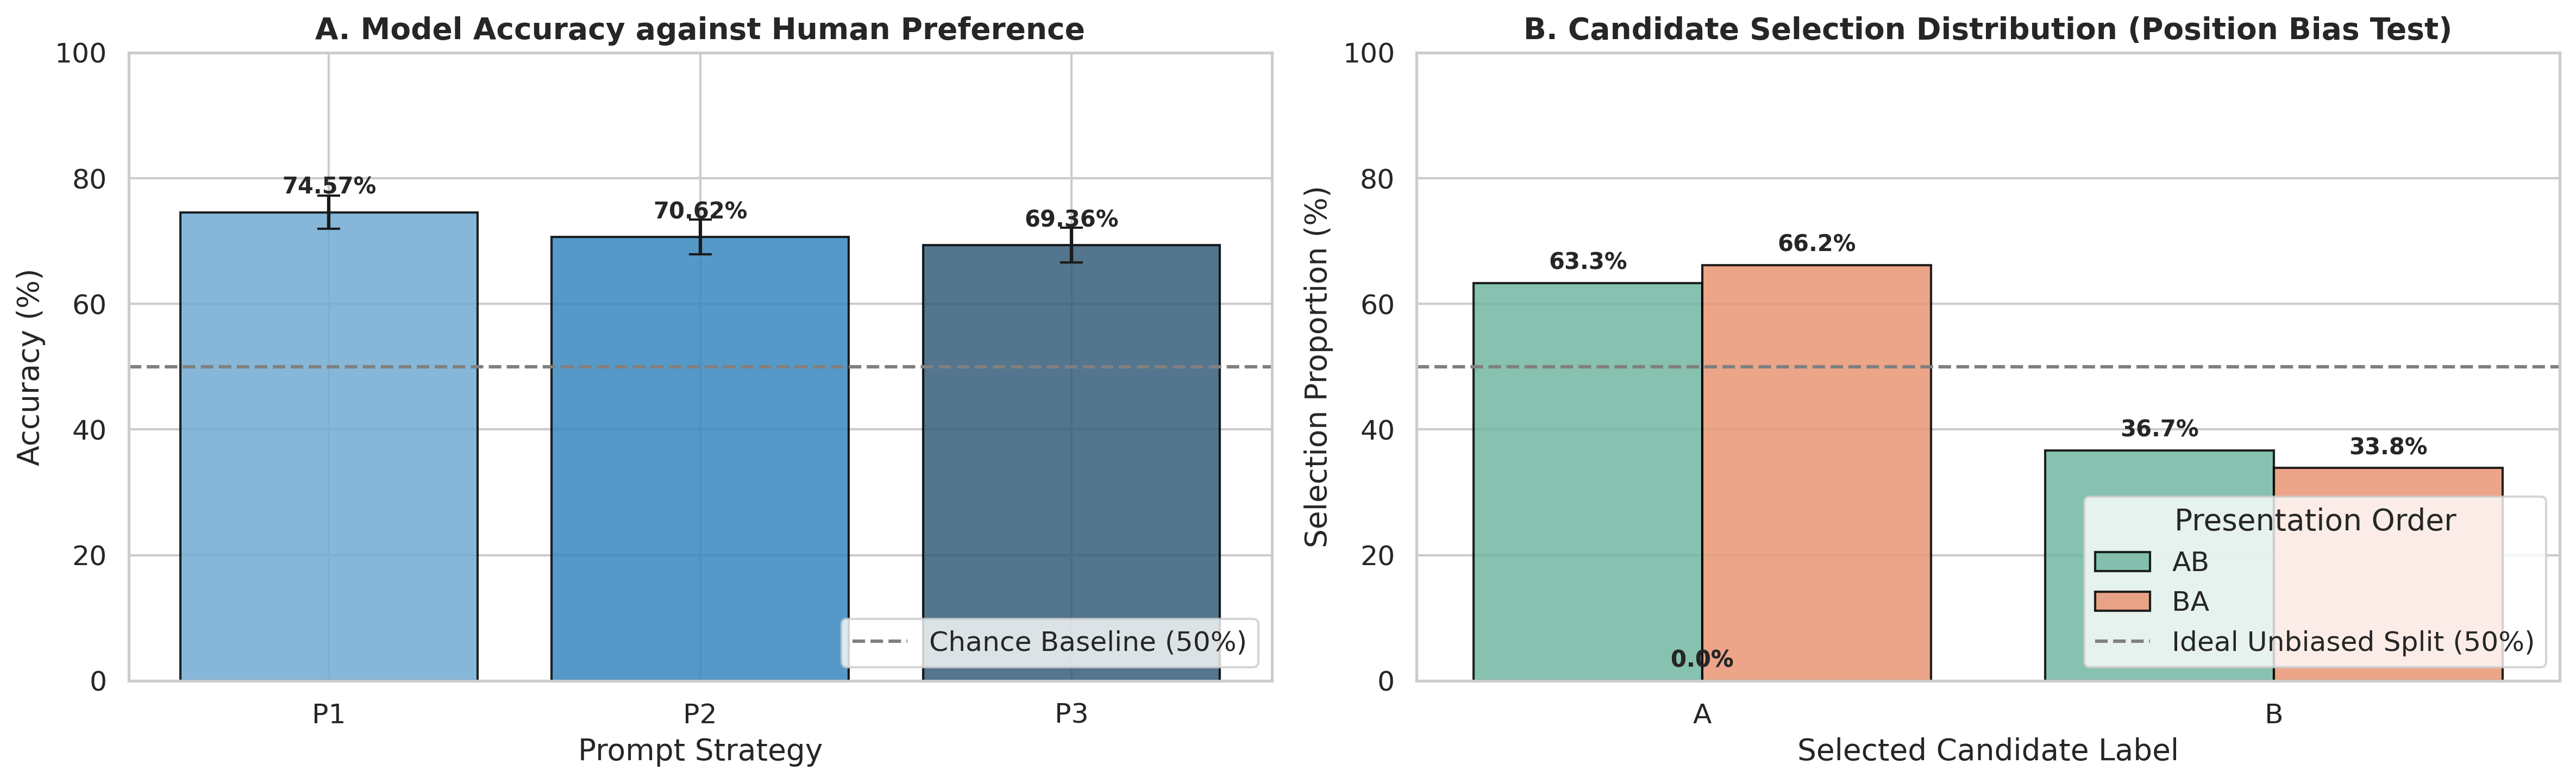

[VISUALIZATION] figure='Fig 1 - Accuracy & Position Distribution' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


In [33]:
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 5))

acc_vals, acc_errs = [], []

for p_id in prompts:
    sub_p = df_valid[df_valid['prompt_id'] == p_id]
    n_p = len(sub_p)
    if n_p > 0:
        correct_s = (sub_p['logical_decision'] == sub_p['logical_human']).astype(int)
        p_mean = correct_s.mean()
        acc_vals.append(p_mean * 100)
        acc_errs.append(1.96 * np.sqrt((p_mean * (1.0 - p_mean)) / n_p) * 100)
    else:
        acc_vals.append(0.0)
        acc_errs.append(0.0)

bars1_a = axes1[0].bar(prompts, acc_vals, yerr=acc_errs, capsize=5,
                       color=sns.color_palette('Blues_d', len(prompts)), edgecolor='black', alpha=0.85)
axes1[0].axhline(50.0, color='gray', linestyle='--', linewidth=1.5, label='Chance Baseline (50%)')
configure_axis(axes1[0], title='A. Model Accuracy against Human Preference',
               xlabel='Prompt Strategy', ylabel='Accuracy (%)', ylim=(0, 100))
axes1[0].legend(loc='lower right')
annotate_bars(axes1[0], bars=bars1_a, fmt="{:.2f}%", offset_y=6)

df_pos_rate = df_valid.groupby(['position', 'parsed_decision']).size().unstack(fill_value=0)
df_pos_pct = df_pos_rate.div(df_pos_rate.sum(axis=1), axis=0) * 100
df_pos_plot = df_pos_pct.reset_index().melt(id_vars='position', value_name='Percentage (%)', var_name='Candidate')

sns.barplot(data=df_pos_plot, x='Candidate', y='Percentage (%)', hue='position',
            ax=axes1[1], palette='Set2', edgecolor='black', alpha=0.85)
axes1[1].axhline(50.0, color='gray', linestyle='--', linewidth=1.5, label='Ideal Unbiased Split (50%)')
configure_axis(axes1[1], title='B. Candidate Selection Distribution (Position Bias Test)',
               xlabel='Selected Candidate Label', ylabel='Selection Proportion (%)', ylim=(0, 100))
axes1[1].legend(title='Presentation Order', loc='lower right')
annotate_bars(axes1[1], fmt="{:.1f}%", offset_y=4)

export_figure(fig1, 'plot_accuracy_and_position_bias', 'Fig 1 - Accuracy & Position Distribution')

### **8.3 Figure 2: Consistency and Cohen Kappa Profile**

- **A. Positional Consistency:** persentase keputusan yang konsisten setelah pertukaran posisi.
- **B. Decision Flip Rate:** persentase keputusan yang berubah.
- **C. Cohen's Kappa:** kesepakatan dengan preferensi manusia beserta interval kepercayaan bootstrap 95%.

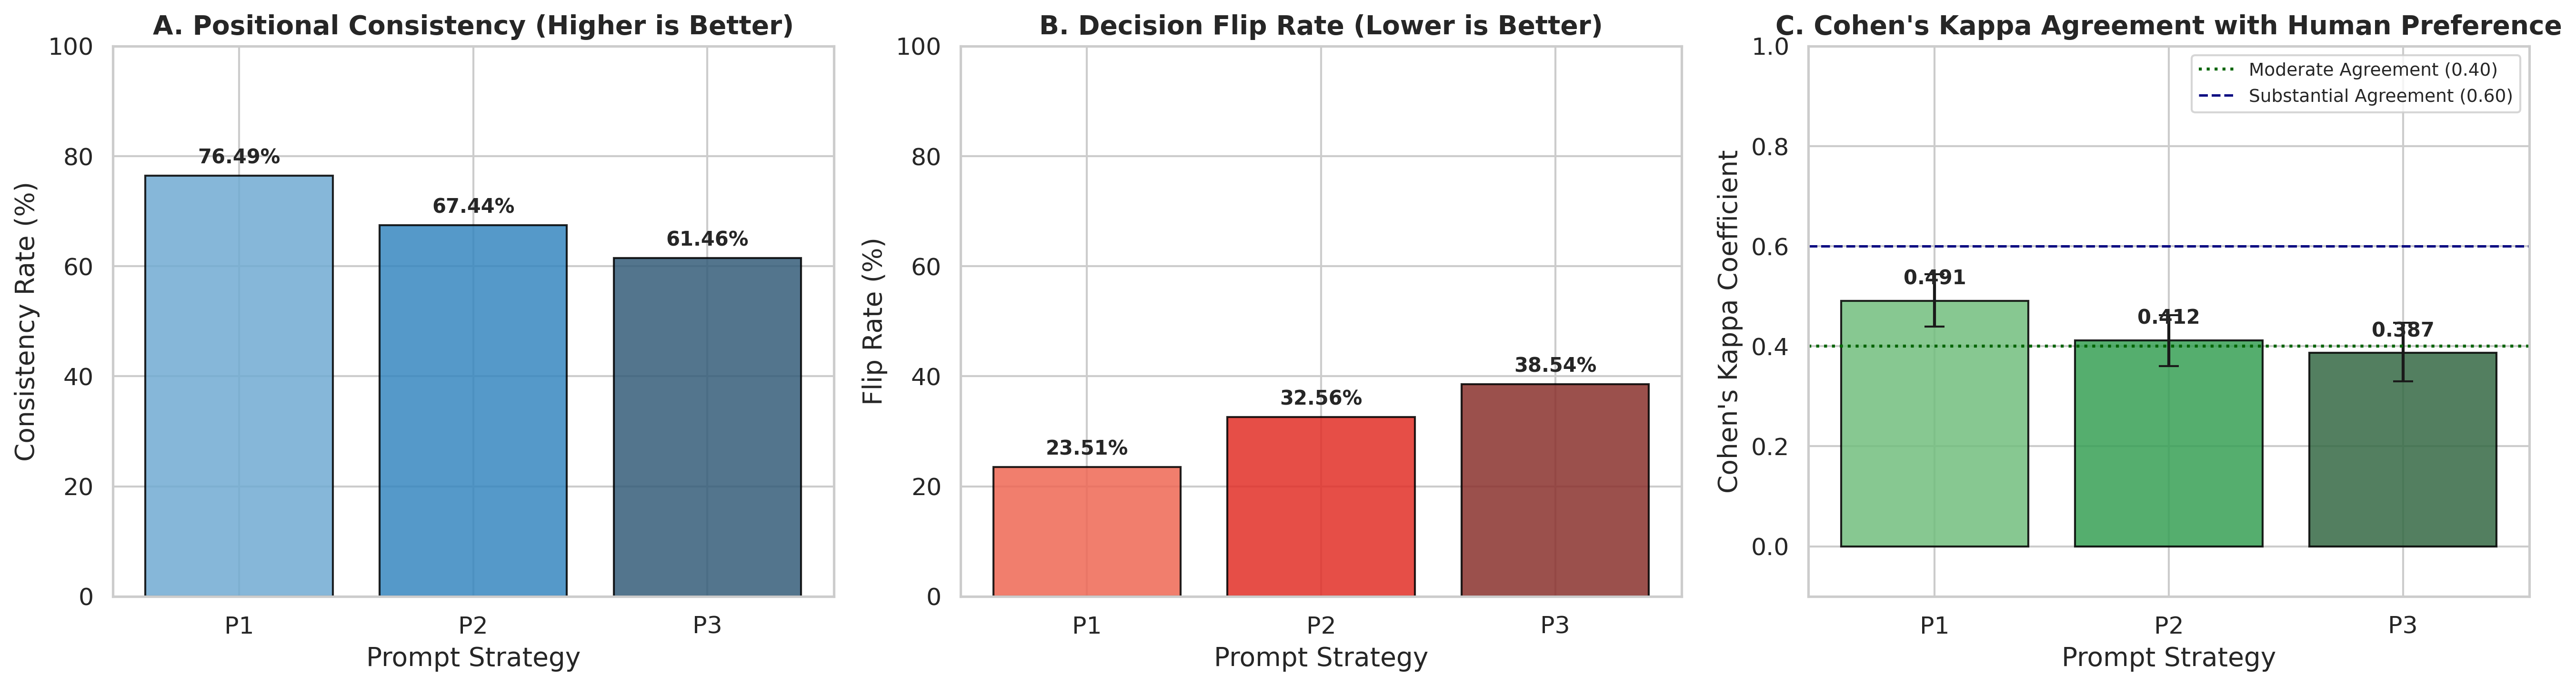

[VISUALIZATION] figure='Fig 2 - Consistency, Flip Rate & Kappa' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


In [34]:
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

bars_2a = axes2[0].bar(df_metrics_table['Prompt'], df_metrics_table['Consistency (%)'],
                       color=sns.color_palette('Blues_d', len(prompts)), edgecolor='black', alpha=0.85)
configure_axis(axes2[0], title='A. Positional Consistency (Higher is Better)',
               xlabel='Prompt Strategy', ylabel='Consistency Rate (%)', ylim=(0, 100))
annotate_bars(axes2[0], bars=bars_2a, fmt="{:.2f}%", offset_y=4)

bars_2b = axes2[1].bar(df_metrics_table['Prompt'], df_metrics_table['Flip Rate (%)'],
                       color=sns.color_palette('Reds_d', len(prompts)), edgecolor='black', alpha=0.85)
configure_axis(axes2[1], title='B. Decision Flip Rate (Lower is Better)',
               xlabel='Prompt Strategy', ylabel='Flip Rate (%)', ylim=(0, 100))
annotate_bars(axes2[1], bars=bars_2b, fmt="{:.2f}%", offset_y=4)

kappa_vals = df_metrics_table['Cohen Kappa'].tolist()
kappa_err_low, kappa_err_high = [], []
for _, row in df_metrics_table.iterrows():
    ci_parts = [float(x.strip()) for x in str(row['Kappa 95% CI']).strip('[]').split(',')]
    k_val = float(row['Cohen Kappa'])
    kappa_err_low.append(max(0.0, k_val - ci_parts[0]))
    kappa_err_high.append(max(0.0, ci_parts[1] - k_val))

bars_2c = axes2[2].bar(df_metrics_table['Prompt'], kappa_vals, yerr=[kappa_err_low, kappa_err_high], capsize=5,
                       color=sns.color_palette('Greens_d', len(prompts)), edgecolor='black', alpha=0.85)
axes2[2].axhline(0.40, color='darkgreen', linestyle=':', linewidth=1.5, label='Moderate Agreement (0.40)')
axes2[2].axhline(0.60, color='navy', linestyle='--', linewidth=1.2, label='Substantial Agreement (0.60)')
configure_axis(axes2[2], title="C. Cohen's Kappa Agreement with Human Preference",
               xlabel='Prompt Strategy', ylabel="Cohen's Kappa Coefficient", ylim=(-0.1, 1.0))
axes2[2].legend(loc='upper right', fontsize=9)
annotate_bars(axes2[2], bars=bars_2c, fmt="{:.3f}", offset_y=6)

export_figure(fig2, 'plot_consistency_and_kappa', 'Fig 2 - Consistency, Flip Rate & Kappa')

### **8.4 Figure 3: Semantic Parsing and Domain Accuracy**

- **A. Decision Format Parsing Success Ratio:** jumlah dan persentase keluaran valid serta `INVALID`.
- **B. Model Evaluator Accuracy across Topical Domains:** akurasi pada setiap domain dan rata-rata keseluruhan.

[DATASET] table='Domain Accuracy Summary' | path='/content/drive/MyDrive/LLMReliability/results/domain_accuracy_summary.csv' | status=EXPORTED


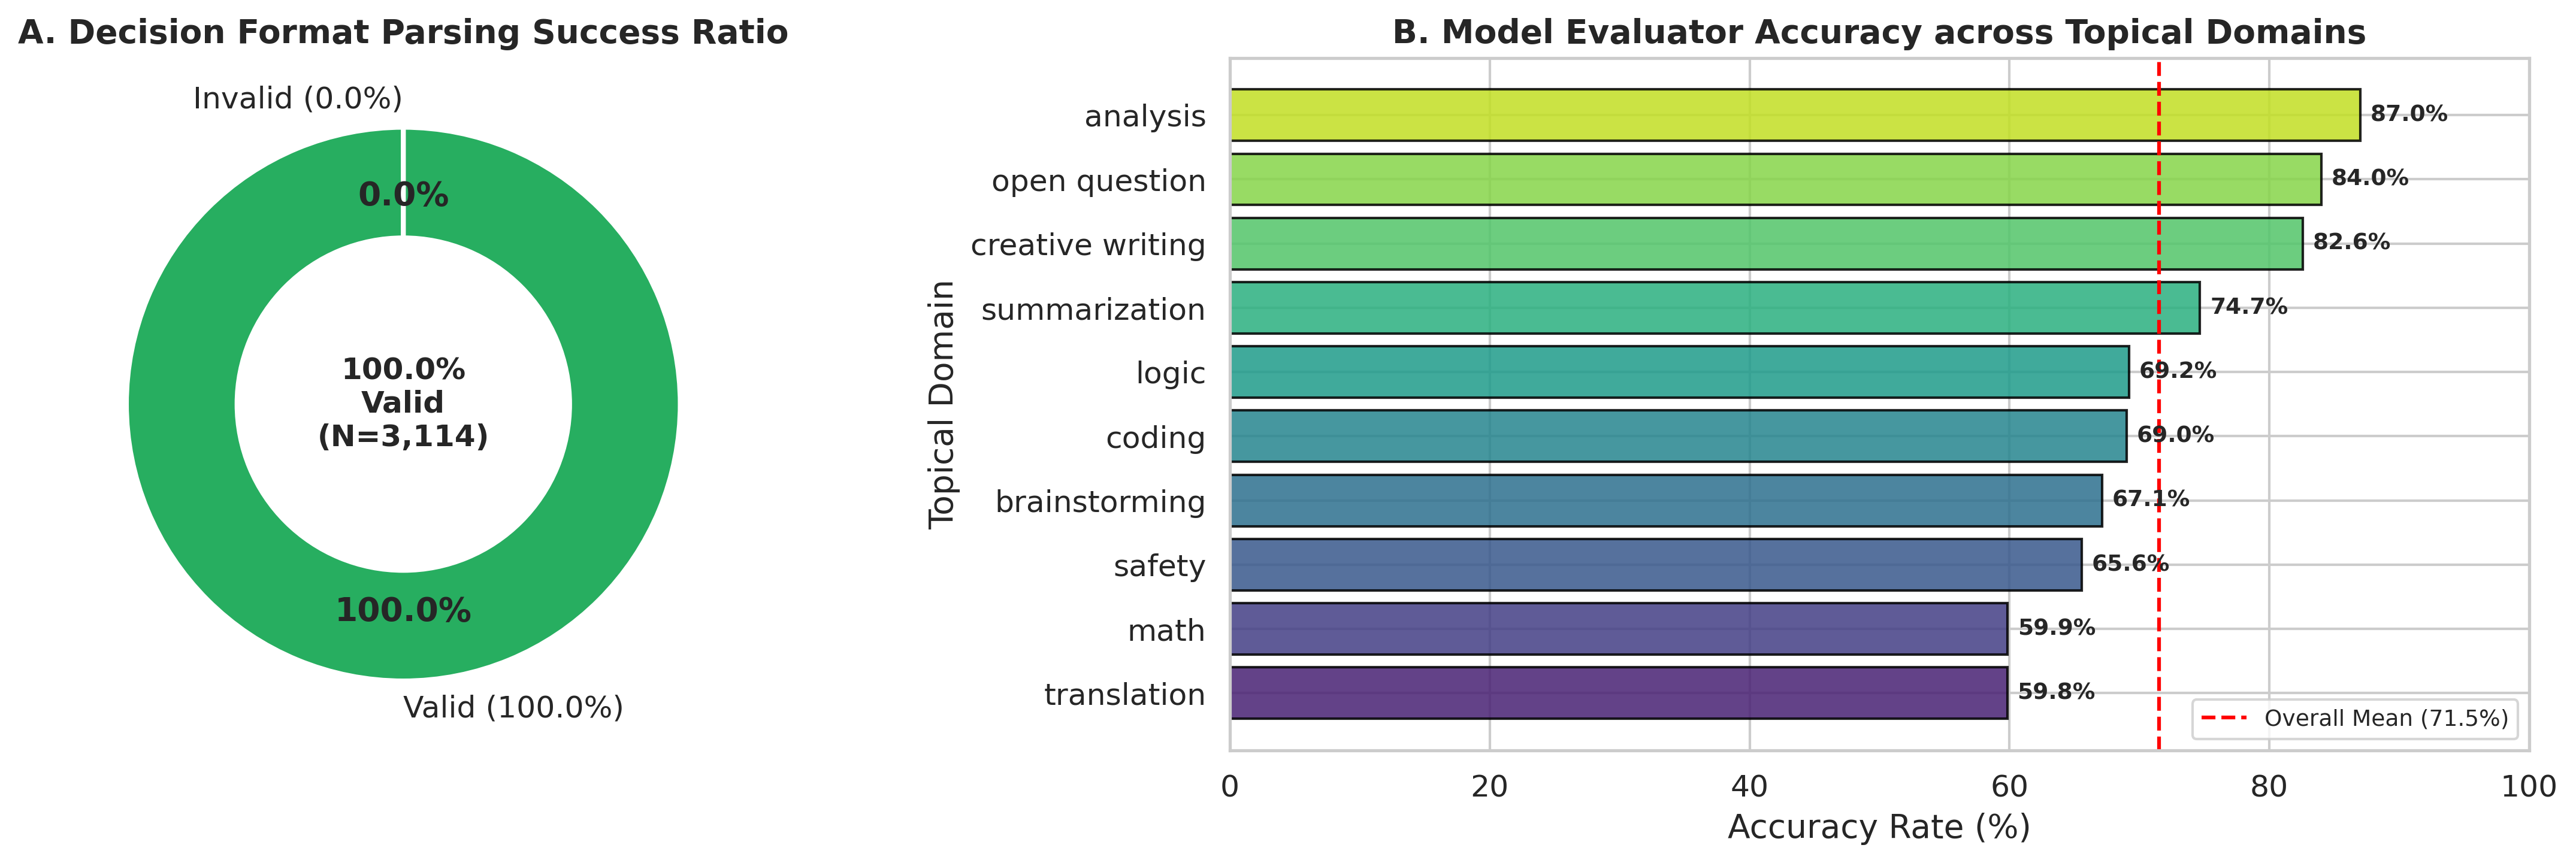

[VISUALIZATION] figure='Fig 3 - Semantic Parsing & Domain Accuracy' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


In [35]:
fig3, axes3 = plt.subplots(1, 2, figsize=(16, 5))

total_eval = len(df_valid) + invalid_count
valid_pct = (len(df_valid) / total_eval) * 100 if total_eval > 0 else 0.0
invalid_pct = (invalid_count / total_eval) * 100 if total_eval > 0 else 0.0

wedges, texts, autotexts = axes3[0].pie(
    [len(df_valid), invalid_count],
    labels=[f"Valid ({valid_pct:.1f}%)", f"Invalid ({invalid_pct:.1f}%)"],
    autopct='%1.1f%%',
    colors=['#27ae60', '#e74c3c'],
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
for autotext in autotexts:
    autotext.set_fontweight('bold')

axes3[0].text(0, 0, f"{valid_pct:.1f}%\nValid\n(N={total_eval:,})", ha='center', va='center', fontweight='bold', fontsize=12)
axes3[0].set_title('A. Decision Format Parsing Success Ratio', fontweight='bold')

df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int) * 100
domain_acc = df_valid.groupby('domain')['is_correct'].mean().reset_index().sort_values('is_correct', ascending=True)
overall_mean_acc = float(df_valid['is_correct'].mean())

domain_csv: str = os.path.join(RESULTS_DIR, 'domain_accuracy_summary.csv')
domain_acc.sort_values('is_correct', ascending=False).to_csv(domain_csv, index=False)
print(f"[DATASET] table='Domain Accuracy Summary' | path='{domain_csv}' | status=EXPORTED")

bars_3b = axes3[1].barh(domain_acc['domain'], domain_acc['is_correct'],
                        color=sns.color_palette('viridis', len(domain_acc)), edgecolor='black', alpha=0.85)
axes3[1].axvline(overall_mean_acc, color='red', linestyle='--', linewidth=1.5, label=f'Overall Mean ({overall_mean_acc:.1f}%)')
configure_axis(axes3[1], title='B. Model Evaluator Accuracy across Topical Domains',
               xlabel='Accuracy Rate (%)', ylabel='Topical Domain', xlim=(0, 100))
axes3[1].legend(loc='lower right', fontsize=9)
annotate_bars(axes3[1], bars=bars_3b, fmt="{:.1f}%", offset_x=4, offset_y=0,
              is_horizontal=True, ha='left', va='center', fontsize=9)

export_figure(fig3, 'plot_parsing_and_domain_acc', 'Fig 3 - Semantic Parsing & Domain Accuracy')

### **8.5 Figure 4: Positional Decision Heatmap**

Menampilkan matriks keputusan A/B pada AB dan BA untuk setiap prompt. Nilai diagonal menunjukkan pasangan keluaran dengan label pilihan yang sama.

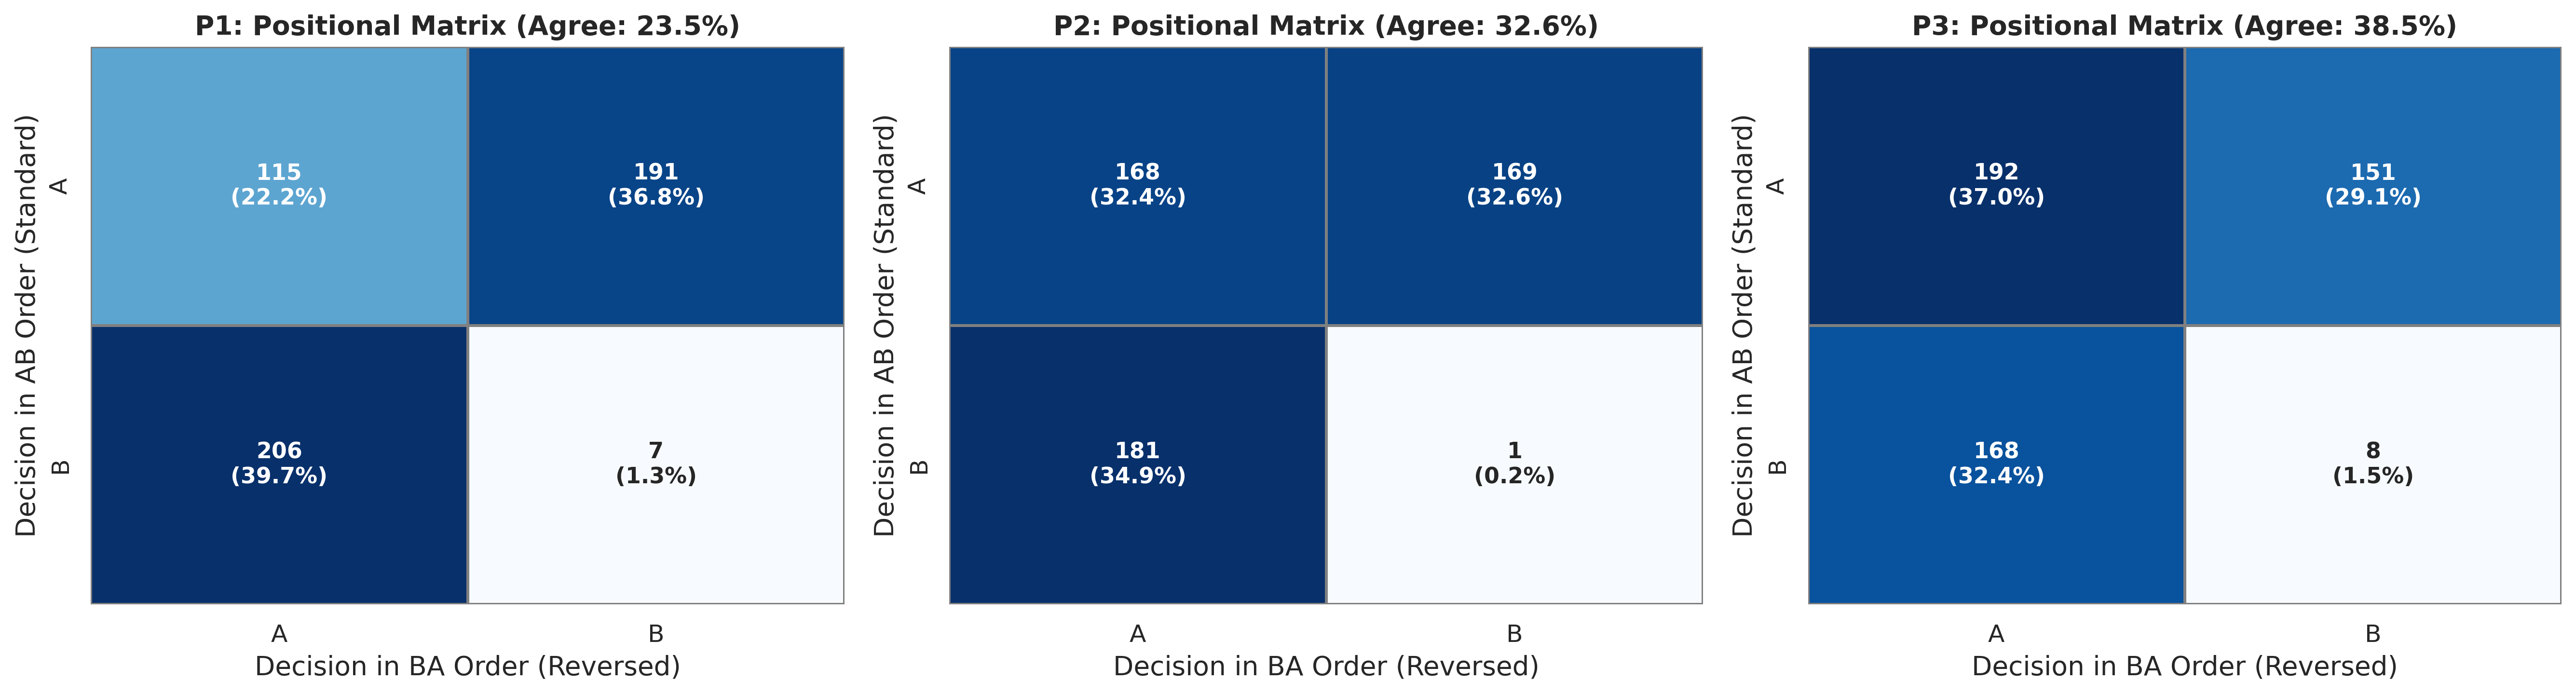

[VISUALIZATION] figure='Fig 4 - Decision Symmetry Heatmaps' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


In [36]:
fig4, axes4 = plt.subplots(1, len(prompts), figsize=(18, 5))

for idx, p_id in enumerate(prompts):
    sub_p = df_valid[df_valid['prompt_id'] == p_id]
    sub_ab = sub_p[sub_p['position'] == 'AB'].set_index('sample_id')
    sub_ba = sub_p[sub_p['position'] == 'BA'].set_index('sample_id')
    paired = sub_ab.join(sub_ba, lsuffix='_ab', rsuffix='_ba', how='inner')

    if not paired.empty:
        crosstab = pd.crosstab(paired['parsed_decision_ab'], paired['parsed_decision_ba'])
        total_paired = len(paired)
        annot_matrix = np.empty(crosstab.shape, dtype=object)
        for i in range(crosstab.shape[0]):
            for j in range(crosstab.shape[1]):
                cnt = crosstab.iloc[i, j]
                pct = (cnt / total_paired) * 100 if total_paired > 0 else 0.0
                annot_matrix[i, j] = f"{cnt}\n({pct:.1f}%)"
        
        diag_agreement = (np.diag(crosstab).sum() / total_paired) * 100 if total_paired > 0 else 0.0

        sns.heatmap(crosstab, annot=annot_matrix, fmt='', cmap='Blues', ax=axes4[idx], cbar=False,
                    annot_kws={'fontsize': 11, 'fontweight': 'bold'},
                    linewidths=1, linecolor='gray')
        configure_axis(axes4[idx], title=f'{p_id}: Positional Matrix (Agree: {diag_agreement:.1f}%)',
                       xlabel='Decision in BA Order (Reversed)', ylabel='Decision in AB Order (Standard)')

export_figure(fig4, 'plot_positional_heatmaps', 'Fig 4 - Decision Symmetry Heatmaps')

### **8.6 Figure 5: Cross-Prompt Stability and Sensitivity Profile**

- **A. Cross-Prompt Decision Consistency:** persentase keputusan yang sama pada setiap pasangan prompt.
- **B. Cross-Prompt Decision Flip Rate:** persentase keputusan yang berbeda pada setiap pasangan prompt.

Perbandingan mencakup P1 vs P2, P1 vs P3, dan P2 vs P3 pada posisi AB.

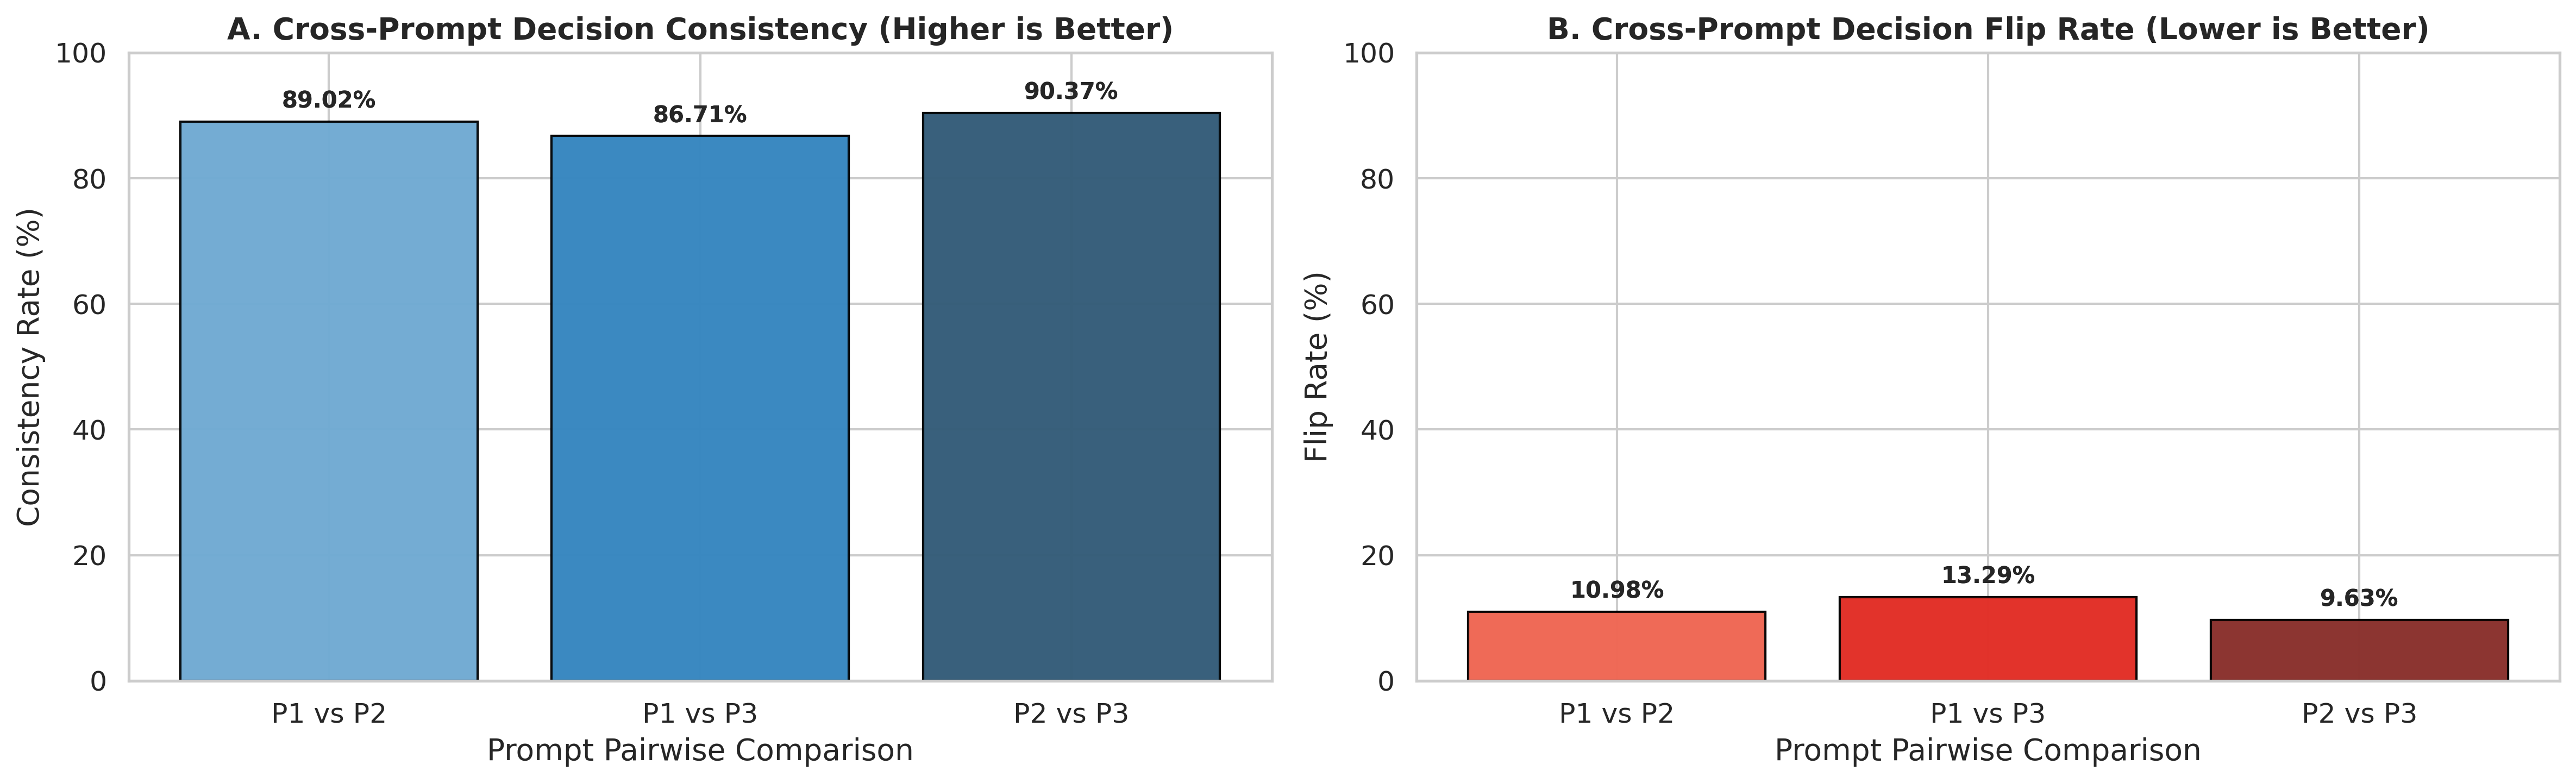

[VISUALIZATION] figure='Fig 5 - Prompt Stability & Sensitivity' | formats=['PNG', 'SVG'] | dir='/content/drive/MyDrive/LLMReliability/results' | status=SAVED


In [37]:
if 'df_prompt_stab' not in globals() or df_prompt_stab is None or df_prompt_stab.empty:
    df_prompt_stab = df_valid[df_valid['position'] == 'AB'].pivot_table(
        index='sample_id', columns='prompt_id', values='logical_decision'
    ).dropna()

if not df_prompt_stab.empty:
    pairs = [('P1 vs P2', 'P1', 'P2'), ('P1 vs P3', 'P1', 'P3'), ('P2 vs P3', 'P2', 'P3')]
    pair_labels = [label for label, _, _ in pairs]
    consistency_rates = [float((df_prompt_stab[p_a] == df_prompt_stab[p_b]).mean() * 100) for _, p_a, p_b in pairs]
    flip_rates = [float((df_prompt_stab[p_a] != df_prompt_stab[p_b]).mean() * 100) for _, p_a, p_b in pairs]

    for label, p_a, p_b in pairs:
        pair_labels.append(label)
        c_rate = (df_prompt_stab[p_a] == df_prompt_stab[p_b]).mean() * 100
        f_rate = (df_prompt_stab[p_a] != df_prompt_stab[p_b]).mean() * 100
        consistency_rates.append(c_rate)
        flip_rates.append(f_rate)

    fig5, axes5 = plt.subplots(1, 2, figsize=(16, 5))

    bars_5a = axes5[0].bar(pair_labels, consistency_rates,
                           color=sns.color_palette('Blues_d', len(pairs)), edgecolor='black', alpha=0.85)
    configure_axis(axes5[0], title='A. Cross-Prompt Decision Consistency (Higher is Better)',
                   xlabel='Prompt Pairwise Comparison', ylabel='Consistency Rate (%)', ylim=(0, 100))
    annotate_bars(axes5[0], bars=bars_5a, fmt="{:.2f}%", offset_y=4)

    bars_5b = axes5[1].bar(pair_labels, flip_rates,
                           color=sns.color_palette('Reds_d', len(pairs)), edgecolor='black', alpha=0.85)
    configure_axis(axes5[1], title='B. Cross-Prompt Decision Flip Rate (Lower is Better)',
                   xlabel='Prompt Pairwise Comparison', ylabel='Flip Rate (%)', ylim=(0, 100))
    annotate_bars(axes5[1], bars=bars_5b, fmt="{:.2f}%", offset_y=4)

    export_figure(fig5, 'plot_prompt_stability_and_sensitivity', 'Fig 5 - Prompt Stability & Sensitivity')